# Mapping Fisher information in the options market

This notebook maps out the Fisher information across the options market to find any areas on the strike-maturity surface that provide systematically higher Fisher information about the Heston model parameters. These specific areas can then be exploited for faster calibration of the Heston model by selecting a smaller, more informative subset of options.

1) **Simulated market data** 

Options data is generated, given market rate, spot price, dividend yield and a range of strike prices and maturities for option contracts

2) **Fisher information across the options market**

The Fisher information is calculated for every point on the strike-maturity surface to find any systematic areas of higher Fisher information that could be exploited for faster calibration of the Heston model using a reduced subset of options

3) **D-optimality subset selection**

A subset selection is performed based on the D-optimality criterion and the calculated Fisher information


In [38]:
import numpy as np
import matplotlib.pyplot as plt

from pricing.heston_cf import price_heston_call
from calibration.heston_calib import calibrate_heston
from calibration.fisher import price_sensitivity, scale_fisher_matrix
from calibration.selection import greedy_d_optimal_selection

from calibration.evaluation_simulation import evaluate_subset

In [ ]:
import calibration.fisher
import importlib
importlib.reload(calibration.fisher)

<module 'calibration.fisher' from 'C:\\Users\\xprp2\\Documents\\python\\derivatives-research\\src\\calibration\\fisher.py'>

## 1) Simulated market data

Synthetic market options are generated using a Heston model consisting of 28 options across 7 strikes and 4 maturities. Gaussian noise is added to the option prices to simulate market observation noise.

These options are then investigated to qualitatively evaluate the presence for areas on the strike-maturity surface that provide higher Fisher information about the Heston parameters.

In [8]:
true_param = {"v0": 0.04, "kappa": 2.0, "theta": 0.04, "ksi": 0.5, "rho": -0.7}

# Simulated market data
strikes = np.array([80, 90, 95, 100, 105, 110, 120])

maturities = np.array([0.25, 0.5, 1.0, 2.0])

S0 = 100.0
rate = 0.05
dividend_yield = 0.0

# x dollar of noise to market price
noise_std = 0.1

In [9]:
# Simulated prices
market_data_noise = []
rng = np.random.default_rng(5)

for T in maturities:
    for K in strikes:
        true_price = price_heston_call(S0=S0, K=K, v0=true_param["v0"], rate=rate, dividend_yield=dividend_yield,
            kappa=true_param["kappa"], theta=true_param["theta"], ksi=true_param["ksi"], rho=true_param["rho"], T=T)

        noise = rng.normal(0.0, noise_std)
        market_data_noise.append({"strike": K, "maturity": T, "true_price": true_price, "price": true_price + noise})

## 2) Mapping Fisher information over the options market

The Fisher information is calculated across the simulated options market to qualitatively evaluate the presence of areas that provide higher information for the estimation of the Heston parameters.

In [ ]:
# Calibration
initial_guess = np.array([0.08,  # v0
                        1.0,  # kappa
                        0.08,  # theta
                        0.3,   # ksi
                        -0.3  # rho
                        ])

result = calibrate_heston(initial_guess=initial_guess, market_data=market_data_noise, S0=S0, rate=rate, dividend_yield=dividend_yield)
print('Result', result.x)
estimated_params = result.x
parameter_names = ["v0","kappa","theta","ksi","rho"]
true_values = np.array([true_param["v0"],true_param["kappa"],true_param["theta"],true_param["ksi"],true_param["rho"]])

for name, true_value, estimated_value in zip(parameter_names, true_values, estimated_params):
    print(f"{name}: " f"true = {true_value:.6f}, " f"estimated = {estimated_value:.6f}")

Result [ 0.03958027  1.73027317  0.04064707  0.49709981 -0.67182289]
v0: true = 0.040000, estimated = 0.039580
kappa: true = 2.000000, estimated = 1.730273
theta: true = 0.040000, estimated = 0.040647
ksi: true = 0.500000, estimated = 0.497100
rho: true = -0.700000, estimated = -0.671823


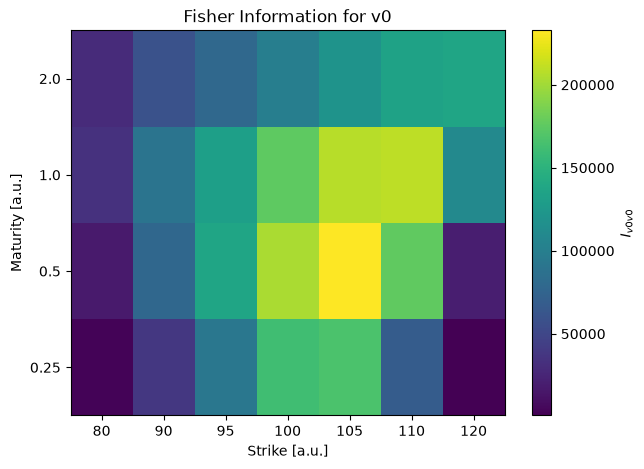

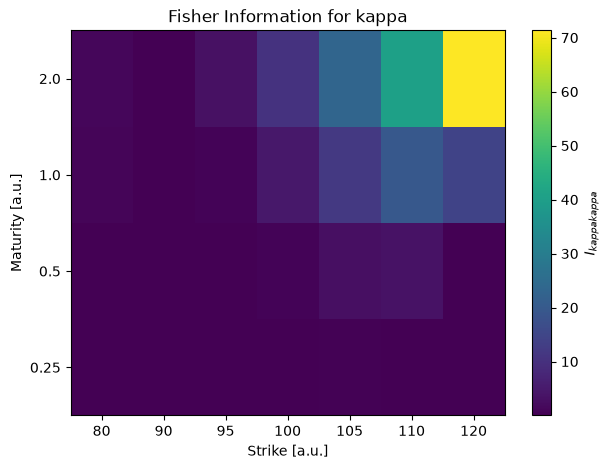

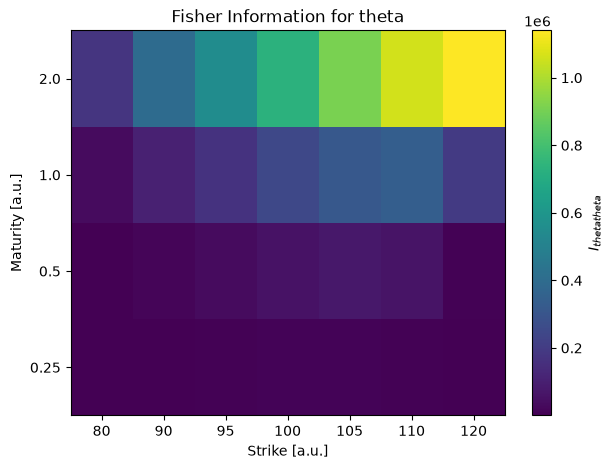

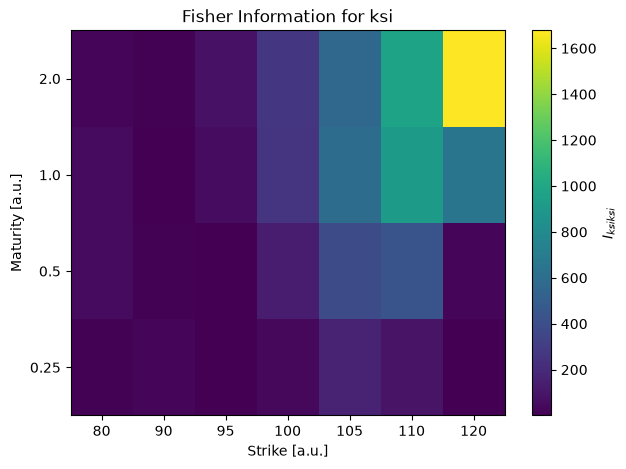

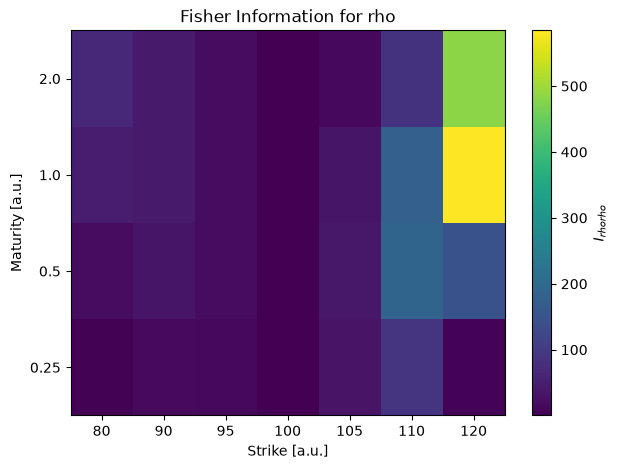

In [ ]:
noise_std_fisher = noise_std

fisher_matrices = {}

for T in maturities:
    for K in strikes:
        jacobian = price_sensitivity(params=estimated_params, K=K, T=T, S0=S0, rate=rate, dividend_yield=dividend_yield) 
        noise_std_fisher = noise_std
        jacobian = jacobian.reshape(1, -1)

        fisher_matrices[(T, K)] = (jacobian.T @ jacobian/noise_std_fisher**2)

trace_fisher = {(T, K): np.trace(I) for (T, K), I in fisher_matrices.items()}
trace_matrix = np.array([[trace_fisher[(T, K)] for K in strikes] for T in maturities])

parameter_names = ["v0", "kappa", "theta", "ksi", "rho"]

for j, parameter in enumerate(parameter_names):

    parameter_matrix = np.array([[fisher_matrices[(T, K)][j, j] for K in strikes] for T in maturities])
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(parameter_matrix, aspect="auto", origin="lower")
    ax.set_xticks(np.arange(len(strikes)))
    ax.set_xticklabels(strikes)
    ax.set_yticks(np.arange(len(maturities)))
    ax.set_yticklabels(maturities)
    ax.set_xlabel("Strike [a.u.]")
    ax.set_ylabel("Maturity [a.u.]")
    ax.set_title(f"Fisher Information for {parameter}")

    fig.colorbar(im, ax=ax, label=fr"$I_{{{parameter}{parameter}}}$")
    plt.show()


The Fisher information maps show that the information about the Heston parameters is not evenly distributed across the options market. Distinct regions of the strike–maturity surface provide systematically higher information about different model parameters. This means that some subsets of options are more informative about the Heston parameters than others.

The next section uses the Fisher information to perform D-optimal subset selection, aiming to identify a compact set of options that maximises joint information about the Heston parameters.

## 3) Subset selection

The Fisher information maps show that information about the Heston parameters is not distributed uniformly across the option market. However, selecting options based only on their individual Fisher information does not necessarily produce the most informative subset, since multiple options may contain highly correlated or redundant information.

To identify a subset that is informative about the Heston parameters as a joint set, we use the D-optimality criterion. For a candidate subset (S), the objective is to maximise

$$
\log \det(F_S)
$$

where ($F_S$) is the Fisher information matrix obtained from the joint set of selected options.

Maximising the determinant favours subsets that provide strong information across all model parameters while avoiding unnecessary redundancy between observations (efficiency). A greedy selection procedure is used by starting from an empty subset and selecting the option that produces the largest increase in (\log\det(F_S)) at each step.

This provides an information-efficient ranking of the available options and allows us to investigate how much of the total Heston parameter information can be retained using only a reduced number of the market observations.

[(np.float64(2.0), np.int64(120)), (np.float64(2.0), np.int64(90)), (np.float64(0.5), np.int64(105)), (np.float64(1.0), np.int64(120)), (np.float64(0.25), np.int64(95)), (np.float64(2.0), np.int64(80)), (np.float64(0.25), np.int64(90)), (np.float64(2.0), np.int64(110)), (np.float64(0.5), np.int64(110)), (np.float64(0.5), np.int64(120))]


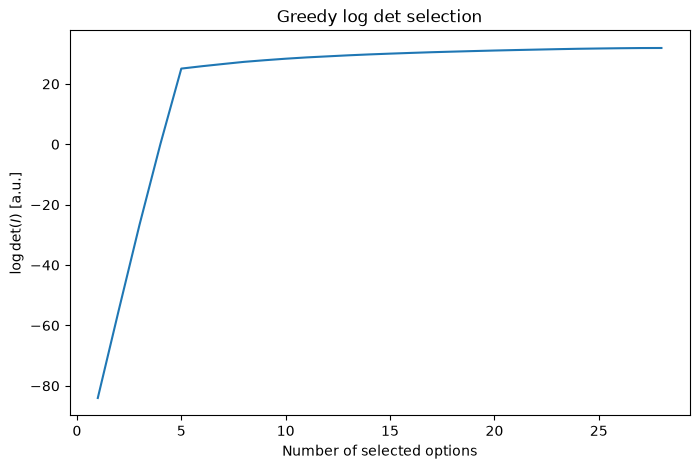

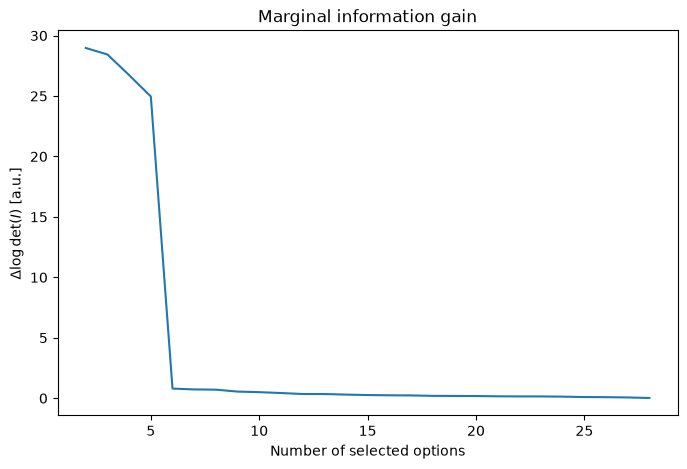

In [14]:
# Selection of most informative option points on strike-maturity surface based on maximising log(det(I)) for 
# sequential selection of option points

# Scale Fisher matrices based on scale of Heston parameters to remove dependence on parameter scale before selecting based on log det
scales = np.array([estimated_params[0], estimated_params[1], estimated_params[2], estimated_params[3], 1.0])
scaled_fisher_matrices = {option: scale_fisher_matrix(I, scales) for option, I in fisher_matrices.items()}

selected, logdet_history = greedy_d_optimal_selection(scaled_fisher_matrices)
print(selected[:10])

n_selected = np.arange(1, len(logdet_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_selected, logdet_history)
plt.xlabel("Number of selected options")
plt.ylabel(r"$\log \det(I)$ [a.u.]")
plt.title("Greedy log det selection")
plt.show()

marginal_gain = np.diff(logdet_history)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(2, len(logdet_history) + 1), marginal_gain)
plt.xlabel("Number of selected options")
plt.ylabel(r"$\Delta \log \det(I)$ [a.u.]")
plt.title("Marginal information gain")
plt.show()

The log-determinant of the joint Fisher information increases rapidly as the first few options are selected, before gradually approaching a plateau. This indicates the most informative options being selected early, while additional options provide progressively less new information for the Heston model.

The marginal information gain shows the same behaviour, with a clear knee where the benefit of adding further observations begins to diminish significantly. This suggests that a reduced subset can capture a large proportion of the available joint parameter information. Selecting additional options beyond this point provides diminishing returns. This behaviour is further investigated to select a subset size for calibration in the next notebook (05_simulated_streaming.ipynb).

# Conclusion
Fisher information exhibits a systematic structure across the option surface, and greedy D-optimal selection can exploit this structure to identify a compact set of observations with high joint Heston parameter information. The results in this notebook indicate a possibility to create a compact, informative set of observations to reduce the computational cost to calibrate the Heston model. This is further worked out and evaluated in notebook 05.

The analysis in this notebook is performed for a fixed parameter state and does not establish whether the selection remains effective when the market evolves. Notebook 05 adds a time dimension to the options simulation to evaluate the selection strategy under simulated sequentially changing market conditions. 